# 03 · Homologación territorial y cobertura

Auditoría del panel municipio×edad. Los 38 códigos con nombre distinto se excluyen como precaución, sin afirmar que los demás códigos garantizan geografía constante.

Fuente: ZIPs CCPC del INE conservados en `datos/raw/`. Se trabaja sobre sus agregaciones verificables en `datos/processed/`. Los resultados representan **grupos estadísticos, no personas individuales**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().resolve()
if not (ROOT/'datos').exists():
    ROOT = ROOT.parent.parent
assert (ROOT/'datos'/'processed').exists(), f'Abra el proyecto raíz, no otro directorio: {ROOT}'
plt.rcParams.update({'figure.figsize':(9,4.3),'figure.dpi':110})


## Panel de seis elecciones y elegibilidad

In [2]:
d=pd.read_csv(ROOT/'datos/processed/matriz_modelo_6_anios.csv')
print('Unidades distintas:',len(d),'| Seis elecciones:',d.completo_6.sum(),'| Aptas:',d.apto_modelo.sum())
display(pd.read_csv(ROOT/'analisis/reportes/cobertura_panel.csv'))
print('LN 2024 cubierto (%):',round(d.loc[d.apto_modelo,'LN_2024'].sum()/d.LN_2024.sum()*100,2))

Unidades distintas: 12385 | Seis elecciones: 11925 | Aptas: 8541


,grupo,n
0,Todas las unidades distintas,12385
1,Con tasa en seis elecciones,11925
2,Con nombre municipal estable,12195
3,Aptas para clustering,8541


LN 2024 cubierto (%): 83.05


## Exclusiones superpuestas: no se suman

,motivo,n_unidades
0,Falta al menos una tasa,460
1,Nombre municipal inconsistente,190
2,<100 observados en alguna elección,863
3,NS >20% en alguna elección,3307


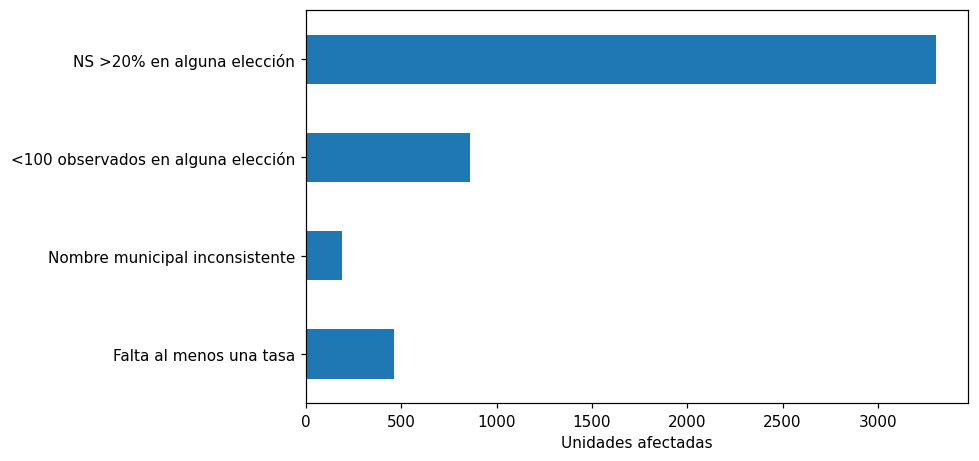

In [3]:
e=pd.read_csv(ROOT/'analisis/reportes/causas_exclusion_superpuestas.csv')
display(e)
ax=e.plot.barh(x='motivo',y='n_unidades',legend=False)
ax.set(xlabel='Unidades afectadas',ylabel='');plt.tight_layout();plt.show()

## Identidad territorial: casos pendientes de correspondencia oficial

In [4]:
m=pd.read_csv(ROOT/'datos/processed/municipios_auditoria_identidad.csv')
issues=m.query('variantes_nombre > 1')
print('Códigos con nombres normalizados incompatibles:',len(issues))
name=pd.read_csv(ROOT/'datos/processed/municipios_nombres_historicos.csv')
display(issues.head(8).merge(name,on=['EDOCVE','MPIOCVE'],how='left')[['EDOCVE','MPIOCVE','anio','MPIONOM']].drop_duplicates().head(25))

Códigos con nombres normalizados incompatibles: 38


,EDOCVE,MPIOCVE,anio,MPIONOM
0,4,6,2009,Hopelchén
1,4,6,2012,Hopelchén
2,4,6,2015,Hopelchén
3,4,6,2018,Hopelchén
4,4,6,2021,Hopelchén
5,4,6,2024,Hopelche}én
6,4,12,2021,Dzitblache
7,4,12,2024,Dzitbalché
8,7,38,2009,Huitiupán
9,7,38,2012,Huitiupán


## Control de sensibilidad a NS y mínimo observado

In [5]:
valid=d.apto_modelo
print('NS máxima (%) entre elegibles: ',d.loc[valid,'max_ns_pct'].describe().round(2).to_string())
print('Observados mínimos entre elegibles:',d.loc[valid,'min_observados'].describe().round(1).to_string())
print('Nota: un umbral de corte es una decisión experimental y debe probarse contra exclusiones.')

NS máxima (%) entre elegibles:  count    8541.00
mean        7.45
std         5.83
min         0.00
25%         2.23
50%         6.92
75%        11.86
max        20.00
Observados mínimos entre elegibles: count      8541.0
mean       7008.7
std       20871.3
min         100.0
25%         711.0
50%        1905.0
75%        4552.0
max      315305.0
Nota: un umbral de corte es una decisión experimental y debe probarse contra exclusiones.
